# Classificação de Dígitos no SVHN — Classificador Linear, MLP e CNN

**Grupo:** João Pedro, Samyr e Valber

Notebook com a implementação e todos os experimentos do trabalho. Ele é autossuficiente: a primeira célula grava
`svhn_lib.py` (modelos, laço de treino, avaliação, gráficos e predição) e as demais executam os experimentos.

**Como rodar**
- **Local:** `jupyter notebook trabalho_svhn.ipynb` (roda em CPU; cerca de 4 a 5 h no total).
- **Colab:** basta abrir este notebook e executar tudo (ative a GPU em *Ambiente de execução → Alterar tipo*).

**Protocolo**
- Dados: `torchvision.datasets.SVHN`, `split="train"` (73.257 imagens) e `split="test"` (26.032).
- O `train` é dividido em **90% treino / 10% validação**, com divisão fixa pela semente 42.
- A validação acompanha os experimentos e escolhe o modelo (e a melhor época de cada treino, por checkpoint).
- O `test` só é usado para relatar o desempenho de cada experimento; **não** participa de nenhuma escolha.
- Depois de escolhida a configuração, o modelo final é retreinado com todo o `train` (treino + validação), como o enunciado permite.
- O conjunto adicional do professor é usado **apenas** na última seção, com o modelo final já definido.
- Semente fixa (42) em tudo: rodar de novo reproduz os mesmos números na mesma máquina.

## 0. Implementação (`svhn_lib.py`)

Todo o código reaproveitável fica nesta célula, que grava o arquivo `svhn_lib.py`. Partimos dos notebooks da aula
(classificador linear e MLP) e adaptamos ao SVHN: entrada de 3×32×32 = 3072 valores, divisão treino/validação e
registro de loss e acurácia por época. O arquivo também é coberto por testes automatizados (`tests/`).

In [1]:
%%writefile svhn_lib.py
"""Funções de apoio do trabalho de classificação de dígitos no SVHN.

Tudo que o notebook usa fica aqui para poder ser testado (tests/) e reaproveitado
pelo script de predição do conjunto adicional.
"""
import copy
import os
import random
import re
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
N_CLASSES = 10
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tif", ".tiff", ".webp"}


# ---------------------------------------------------------------------------
# Reprodutibilidade
# ---------------------------------------------------------------------------

def set_seed(seed: int = SEED) -> None:
    """Fixa todas as sementes (Python, NumPy, PyTorch CPU/GPU)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device() -> torch.device:
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ---------------------------------------------------------------------------
# Dados
# ---------------------------------------------------------------------------

def load_parquet_split(path):
    """Lê um split do espelho oficial do SVHN no Hugging Face (ufldl-stanford/svhn, cropped_digits).

    Mesmas imagens, mesma ordem e mesmos rótulos (0-9) de torchvision.datasets.SVHN.
    """
    import io

    import pandas as pd
    from PIL import Image

    df = pd.read_parquet(path)
    X = np.stack([np.asarray(Image.open(io.BytesIO(im["bytes"])).convert("RGB"), dtype=np.uint8)
                  for im in df["image"]]).transpose(0, 3, 1, 2)
    return torch.from_numpy(np.ascontiguousarray(X)), torch.tensor(df["label"].to_numpy(), dtype=torch.int64)


def load_svhn(root: str = "data", hf_root: str = "data_hf"):
    """Carrega os splits 'train' e 'test' do SVHN como tensores uint8 (N, 3, 32, 32).

    Usa torchvision.datasets.SVHN (que converte o rótulo 10 do .mat para 0). Se os .mat não
    estiverem em `root` mas houver o espelho parquet em `hf_root` (servidor de Stanford instável),
    lê dele — o conteúdo e a ordem são os mesmos.
    """
    import torchvision

    out = []
    for split in ("train", "test"):
        pq = Path(hf_root) / f"{split}.parquet"
        if not (Path(root) / f"{split}_32x32.mat").exists() and pq.exists():
            out.append(load_parquet_split(pq))
            continue
        ds = torchvision.datasets.SVHN(root=root, split=split, download=True)
        X = torch.from_numpy(ds.data)  # já vem em (N, 3, 32, 32), uint8
        y = torch.from_numpy(ds.labels.astype(np.int64))
        out.append((X, y))
    return out[0], out[1]


def split_train_val(n: int, val_frac: float = 0.1, seed: int = SEED):
    """Índices de treino/validação: embaralhamento fixo pela semente."""
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    n_val = int(round(n * val_frac))
    return perm[n_val:], perm[:n_val]


def compute_norm_stats(X: torch.Tensor):
    """Média e desvio padrão por canal (em escala [0, 1]), calculados só no treino.

    Usa somas inteiras exatas dos pixels uint8. Somar dezenas de milhões de valores em float32
    dá resultados que mudam na 7ª casa conforme a ordem da soma (número de threads, alinhamento
    de memória), e essa diferença se amplifica no treino; com inteiros, o resultado é sempre o
    mesmo, o que garante a reprodutibilidade.
    """
    means, stds = [], []
    for c in range(X.shape[1]):
        xc = X[:, c].to(torch.int64)
        n, s, ss = xc.numel(), int(xc.sum()), int((xc * xc).sum())  # inteiros exatos
        means.append(s / n / 255.0)
        stds.append(((ss * n - s * s) / (n * (n - 1))) ** 0.5 / 255.0)  # desvio amostral (n - 1)
    return torch.tensor(means, dtype=torch.float32), torch.tensor(stds, dtype=torch.float32)


def preprocess(X: torch.Tensor, mean=None, std=None) -> torch.Tensor:
    """uint8 -> float em [0, 1]; se houver mean/std, normaliza por canal."""
    Xf = X.float() / 255.0
    if mean is not None:
        Xf = (Xf - mean.view(1, -1, 1, 1)) / std.view(1, -1, 1, 1)
    return Xf


def random_shift(x: torch.Tensor, max_shift: int, gen: torch.Generator) -> torch.Tensor:
    """Data augmentation: translada cada imagem até `max_shift` pixels (borda replicada).

    Não usamos flip horizontal porque ele muda o significado de alguns dígitos.
    """
    if max_shift <= 0:
        return x
    B, C, H, W = x.shape
    p = max_shift
    xp = F.pad(x, (p, p, p, p), mode="replicate")
    dx = torch.randint(0, 2 * p + 1, (B,), generator=gen).to(x.device)
    dy = torch.randint(0, 2 * p + 1, (B,), generator=gen).to(x.device)
    rows = dy[:, None] + torch.arange(H, device=x.device)  # (B, H)
    cols = dx[:, None] + torch.arange(W, device=x.device)  # (B, W)
    b = torch.arange(B, device=x.device)[:, None, None]
    out = xp.permute(0, 2, 3, 1)[b, rows[:, :, None], cols[:, None, :]]  # (B, H, W, C)
    return out.permute(0, 3, 1, 2).contiguous()


# ---------------------------------------------------------------------------
# Modelos
# ---------------------------------------------------------------------------

class LinearClassifier(nn.Module):
    """logits = x W + b, com x = imagem achatada (3*32*32 = 3072 entradas)."""

    def __init__(self, in_features: int = 3 * 32 * 32, n_classes: int = N_CLASSES):
        super().__init__()
        self.fc = nn.Linear(in_features, n_classes)

    def forward(self, x):
        return self.fc(x.flatten(1))


class MLP(nn.Module):
    """Rede totalmente conectada com camadas ocultas configuráveis.

    Cada camada oculta: Linear -> [BatchNorm] -> ReLU -> [Dropout].
    """

    def __init__(self, hidden_sizes, dropout: float = 0.0, batchnorm: bool = False,
                 in_features: int = 3 * 32 * 32, n_classes: int = N_CLASSES):
        super().__init__()
        layers, prev = [], in_features
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x.flatten(1))


def _conv_bn(cin, cout):
    return [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU()]


class CNN(nn.Module):
    """CNN pequena: 3 blocos convolucionais (32 -> 64 -> 128 filtros) + classificador MLP."""

    def __init__(self, dropout: float = 0.3, n_classes: int = N_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            *_conv_bn(3, 32), *_conv_bn(32, 32), nn.MaxPool2d(2),     # 32 -> 16
            *_conv_bn(32, 64), *_conv_bn(64, 64), nn.MaxPool2d(2),    # 16 -> 8
            *_conv_bn(64, 128), *_conv_bn(128, 128), nn.MaxPool2d(2),  # 8 -> 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# ---------------------------------------------------------------------------
# Treino e avaliação
# ---------------------------------------------------------------------------

@torch.no_grad()
def evaluate(model, X, y, batch_size: int = 2048, device=None):
    """Retorna (loss média, acurácia) com o modelo em modo de avaliação."""
    device = device or next(model.parameters()).device
    model.eval()
    total_loss, correct = 0.0, 0
    for i in range(0, len(X), batch_size):
        xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
        out = model(xb)
        total_loss += F.cross_entropy(out, yb, reduction="sum").item()
        correct += (out.argmax(1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)


def train_model(model, data, epochs: int, batch_size: int, lr: float,
                optimizer: str = "adam", weight_decay: float = 0.0,
                scheduler: str | None = None, augment_shift: int = 0,
                seed: int = SEED, device=None, verbose: bool = True):
    """Treina `model` e registra loss/acurácia de treino e validação a cada época.

    `data` precisa das chaves X_train, y_train e, opcionalmente, X_val, y_val (tensores já
    pré-processados). Com validação, o modelo termina com os pesos da época de MAIOR acurácia
    de validação (checkpoint do melhor modelo). Sem validação (retreino final com treino +
    validação), termina com os pesos da última época. Retorna o histórico (dict).
    """
    device = device or get_device()
    torch.manual_seed(seed)  # dropout e inicializações tardias
    gen = torch.Generator().manual_seed(seed)  # ordem dos mini-batches e augmentation
    model.to(device)

    if optimizer == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    else:
        raise ValueError(f"otimizador desconhecido: {optimizer}")
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if scheduler == "cosine" else None

    X_tr, y_tr = data["X_train"], data["y_train"]
    has_val = "X_val" in data
    n = len(X_tr)
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "epoch_time")}
    best_acc, best_state, best_epoch = -1.0, None, -1

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        perm = torch.randperm(n, generator=gen)
        run_loss, run_correct = 0.0, 0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb = X_tr[idx]
            if augment_shift:
                xb = random_shift(xb, augment_shift, gen)
            xb, yb = xb.to(device), y_tr[idx].to(device)

            out = model(xb)
            loss = F.cross_entropy(out, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()

            run_loss += loss.item() * len(idx)
            run_correct += (out.argmax(1) == yb).sum().item()
        if sched:
            sched.step()

        hist["train_loss"].append(run_loss / n)
        hist["train_acc"].append(run_correct / n)
        msg = (f"época {epoch + 1:2d}/{epochs} | treino loss {hist['train_loss'][-1]:.4f} "
               f"acc {hist['train_acc'][-1]:.4f}")
        if has_val:
            val_loss, val_acc = evaluate(model, data["X_val"], data["y_val"], device=device)
            hist["val_loss"].append(val_loss)
            hist["val_acc"].append(val_acc)
            msg += f" | val loss {val_loss:.4f} acc {val_acc:.4f}"
            if val_acc > best_acc:
                best_acc, best_epoch = val_acc, epoch
                best_state = copy.deepcopy(model.state_dict())
        hist["epoch_time"].append(time.time() - t0)
        if verbose:
            print(f"{msg} | {hist['epoch_time'][-1]:.1f}s")

    if has_val:
        model.load_state_dict(best_state)
        hist["best_epoch"], hist["best_val_acc"] = best_epoch, best_acc
    else:
        hist["best_epoch"], hist["best_val_acc"] = epochs - 1, None
    return hist


def confusion_matrix(y_true, y_pred, n_classes: int = N_CLASSES) -> torch.Tensor:
    """cm[i, j] = nº de exemplos da classe i preditos como j."""
    idx = y_true.long() * n_classes + y_pred.long()
    return torch.bincount(idx, minlength=n_classes * n_classes).view(n_classes, n_classes)


@torch.no_grad()
def predict(model, X, batch_size: int = 2048, device=None) -> torch.Tensor:
    device = device or next(model.parameters()).device
    model.eval()
    preds = [model(X[i:i + batch_size].to(device)).argmax(1).cpu() for i in range(0, len(X), batch_size)]
    return torch.cat(preds).long()


# ---------------------------------------------------------------------------
# Gráficos
# ---------------------------------------------------------------------------

def plot_history(hist, title: str = "", path=None):
    """Curvas de Loss e Acurácia (treino x validação) ao longo das épocas."""
    import matplotlib.pyplot as plt

    ep = range(1, len(hist["train_loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    a1.plot(ep, hist["train_loss"], label="treino")
    a1.set(xlabel="época", ylabel="loss (cross-entropy)", title="Loss")
    a2.plot(ep, hist["train_acc"], label="treino")
    if hist["val_loss"]:
        a1.plot(ep, hist["val_loss"], label="validação")
        a2.plot(ep, hist["val_acc"], label="validação")
        a2.axvline(hist["best_epoch"] + 1, ls=":", c="gray", label="melhor época (val)")
    a2.set(xlabel="época", ylabel="acurácia", title="Acurácia")
    from matplotlib.ticker import MaxNLocator
    for a in (a1, a2):
        a.xaxis.set_major_locator(MaxNLocator(integer=True))
        a.grid(alpha=0.3)
        a.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=130)
    return fig


# ---------------------------------------------------------------------------
# Conjunto adicional e arquivo de resultados
# ---------------------------------------------------------------------------

def natural_sort_key(name: str):
    """'img_2' < 'img_10' (ordenação numérica, não alfabética)."""
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(name))]


def load_image_folder(folder):
    """Lê todas as imagens da pasta em ordem natural do nome -> (nomes, uint8 (N, 3, 32, 32))."""
    from PIL import Image

    folder = Path(folder)
    names = sorted((p.name for p in folder.iterdir()
                    if p.is_file() and p.suffix.lower() in IMG_EXTS), key=natural_sort_key)
    arrs = []
    for nm in names:
        with Image.open(folder / nm) as im:
            im = im.convert("RGB")
            if im.size != (32, 32):
                im = im.resize((32, 32), Image.BILINEAR)
            arrs.append(np.asarray(im, dtype=np.uint8).transpose(2, 0, 1))
    X = torch.from_numpy(np.stack(arrs)) if arrs else torch.empty(0, 3, 32, 32, dtype=torch.uint8)
    return names, X


def write_results(preds, path) -> None:
    """Grava uma predição (inteiro 0-9) por linha, na ordem recebida."""
    vals = [int(v) for v in (preds.tolist() if hasattr(preds, "tolist") else preds)]
    if any(v < 0 or v > 9 for v in vals):
        raise ValueError("predições devem ser inteiros entre 0 e 9")
    Path(path).write_text("".join(f"{v}\n" for v in vals))

Overwriting svhn_lib.py


In [2]:
import os, sys, json, time, importlib
import svhn_lib
importlib.reload(svhn_lib)
import svhn_lib as L
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
L.set_seed(SEED)
device = L.get_device()
os.makedirs('resultados', exist_ok=True)
os.makedirs('pesos', exist_ok=True)
print('device:', device, '| torch', torch.__version__, '| threads', torch.get_num_threads())

device: cpu | torch 2.15.0+cpu | threads 12


## 1. Dados

In [3]:
(X_all, y_all), (X_test_u8, y_test) = L.load_svhn('data')
idx_tr, idx_va = L.split_train_val(len(X_all), val_frac=0.1, seed=SEED)
X_tr_u8, y_train = X_all[idx_tr], y_all[idx_tr]
X_va_u8, y_val = X_all[idx_va], y_all[idx_va]
print('treino   :', tuple(X_tr_u8.shape))
print('validação:', tuple(X_va_u8.shape))
print('teste    :', tuple(X_test_u8.shape))

treino   : (65931, 3, 32, 32)
validação: (7326, 3, 32, 32)
teste    : (26032, 3, 32, 32)


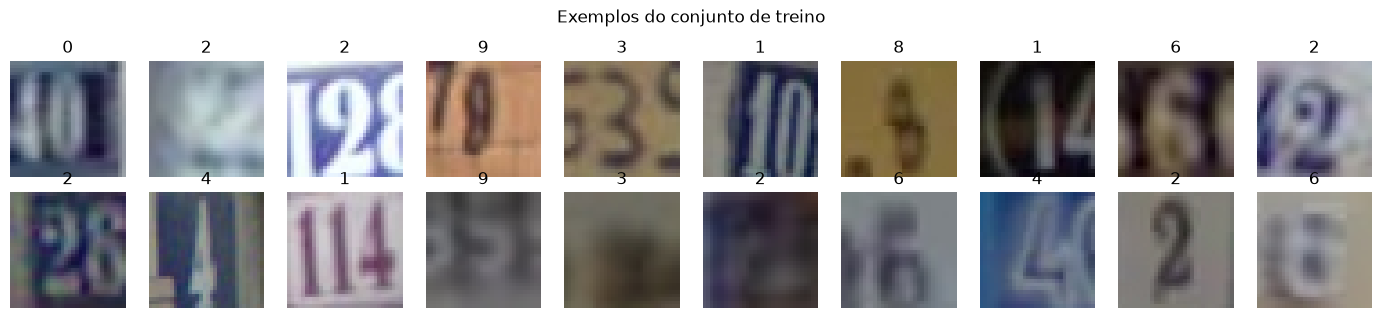

,treino,validação,teste
dígito,,,
0,4506,442,1744
1,12418,1443,5099
2,9475,1110,4149
3,7639,858,2882
4,6717,741,2523
5,6216,666,2384
6,5163,564,1977
7,5068,527,2019
8,4538,507,1660


In [4]:
fig, ax = plt.subplots(2, 10, figsize=(14, 3.2))
for i, a in enumerate(ax.flat):
    a.imshow(X_tr_u8[i].permute(1, 2, 0)); a.set_title(int(y_train[i])); a.axis('off')
plt.suptitle('Exemplos do conjunto de treino'); plt.tight_layout(); plt.savefig('resultados/exemplos.png', dpi=120); plt.show()

dist = pd.DataFrame({s: np.bincount(y.numpy(), minlength=10) for s, y in
                     [('treino', y_train), ('validação', y_val), ('teste', y_test)]})
dist.index.name = 'dígito'; dist

**Pré-processamento.** Duas versões dos dados:
- `bruto`: pixels em [0, 1] (como no notebook da aula, só `ToTensor`).
- `norm`: subtrai a média e divide pelo desvio padrão **de cada canal de cor**, calculados só no treino
  (slide de pré-processamento: "subtraia a média por canal"). Validação e teste usam os mesmos valores, sem vazamento.

In [5]:
mean, std = L.compute_norm_stats(X_tr_u8)
print('média por canal:', mean.numpy().round(4), '| desvio:', std.numpy().round(4))

DATA = {
    'bruto': dict(X_train=L.preprocess(X_tr_u8), y_train=y_train,
                  X_val=L.preprocess(X_va_u8), y_val=y_val,
                  X_test=L.preprocess(X_test_u8), y_test=y_test),
    'norm':  dict(X_train=L.preprocess(X_tr_u8, mean, std), y_train=y_train,
                  X_val=L.preprocess(X_va_u8, mean, std), y_val=y_val,
                  X_test=L.preprocess(X_test_u8, mean, std), y_test=y_test),
}

média por canal: [0.4376 0.4437 0.4727] | desvio: [0.1979 0.2009 0.1969]


**Checagem de sanidade (da aula de loss).** Com pesos iniciais aleatórios, as 10 classes são quase equiprováveis,
então a cross-entropy inicial deve ficar perto de $\ln 10 \approx 2{,}303$ e a acurácia perto de 10%.

In [6]:
L.set_seed(SEED)
for nome, m in [('Linear', L.LinearClassifier()), ('MLP 2×500', L.MLP([500, 500])), ('CNN', L.CNN())]:
    loss0, acc0 = L.evaluate(m, DATA['norm']['X_val'], y_val)
    print(f'{nome:10s} loss inicial = {loss0:.3f} (ln 10 = {np.log(10):.3f}) | acurácia inicial = {acc0:.3f}')

Linear     loss inicial = 2.466 (ln 10 = 2.303) | acurácia inicial = 0.095
MLP 2×500  loss inicial = 2.315 (ln 10 = 2.303) | acurácia inicial = 0.083


CNN        loss inicial = 2.302 (ln 10 = 2.303) | acurácia inicial = 0.072


## 2. Função que roda um experimento

Para cada experimento: fixa a semente, cria o modelo, treina registrando **loss e acurácia de treino e de validação
a cada época**, fica com os pesos da melhor época na validação, mede a acurácia no teste e salva o histórico
(`resultados/*.json`), as curvas (`resultados/*.png`) e os pesos (`pesos/*.pt`).

> A acurácia de treino é a média ao longo da época, com dropout e augmentation ativos. Validação e teste são medidos
> com o modelo em modo `eval`.

In [7]:
RESULTS, REGISTRY = [], {}

def run(exp_id, nome, modificacao, make_model, dados='norm', pai=None, **train_kw):
    print(f'=== E{exp_id}: {nome} ===')
    REGISTRY[exp_id] = (make_model, dados, train_kw)
    L.set_seed(SEED)
    model = make_model()
    data = DATA[dados]
    t0 = time.time()
    hist = L.train_model(model, data, seed=SEED, device=device, **train_kw)
    test_loss, test_acc = L.evaluate(model, data['X_test'], data['y_test'], device=device)
    b = hist['best_epoch']
    row = dict(exp=exp_id, nome=nome, modificacao=modificacao, dados=dados, pai=pai,
               params=L.count_params(model), epocas=train_kw['epochs'], melhor_epoca=b + 1,
               train_loss=hist['train_loss'][b], val_loss=hist['val_loss'][b],
               train_acc=hist['train_acc'][b], val_acc=hist['val_acc'][b],
               test_acc=test_acc, tempo_min=(time.time() - t0) / 60,
               config={k: v for k, v in train_kw.items()})
    RESULTS.append(row)
    torch.save({'state_dict': model.state_dict(), 'row': row}, f'pesos/E{exp_id}.pt')
    with open(f'resultados/E{exp_id}.json', 'w') as f:
        json.dump({'row': row, 'hist': hist}, f, indent=1)
    L.plot_history(hist, f'E{exp_id} — {nome}', f'resultados/E{exp_id}_curvas.png'); plt.show()
    print(f"melhor época {b+1}: train_loss={row['train_loss']:.4f} val_loss={row['val_loss']:.4f} | "
          f"train_acc={row['train_acc']:.4f} val_acc={row['val_acc']:.4f} | test_acc={test_acc:.4f} | {row['tempo_min']:.1f} min")
    return model, hist

## 3. Experimentos

Cada experimento muda **um fator** em relação a um experimento anterior (o "pai", indicado em cada um), para que a
melhora ou a piora possa ser atribuída a esse fator. Quando duas ou mais alternativas são comparadas (taxa de
aprendizado, tamanho do batch), o código segue automaticamente com a de **maior acurácia de validação**.

### E1 — Classificador linear
`logits = x·W + b` sobre os 3072 pixels normalizados, com cross-entropy (softmax) e regularização L2
(`weight_decay`), treinado por gradiente descendente em mini-batches com momentum. É o classificador linear da aula,
agora com `nn.Linear`.

=== E1: Classificador linear ===


época  1/20 | treino loss 2.2920 acc 0.1582 | val loss 2.2603 acc 0.1996 | 1.7s


época  2/20 | treino loss 2.2345 acc 0.2213 | val loss 2.2262 acc 0.2322 | 1.7s


época  3/20 | treino loss 2.2113 acc 0.2374 | val loss 2.2112 acc 0.2502 | 1.7s


época  4/20 | treino loss 2.1984 acc 0.2456 | val loss 2.2006 acc 0.2584 | 1.7s


época  5/20 | treino loss 2.1895 acc 0.2517 | val loss 2.1965 acc 0.2562 | 1.7s


... (11 outputs left out)

época 17/20 | treino loss 2.1477 acc 0.2785 | val loss 2.1608 acc 0.2812 | 1.7s


época 18/20 | treino loss 2.1461 acc 0.2777 | val loss 2.1579 acc 0.2806 | 0.6s


época 19/20 | treino loss 2.1442 acc 0.2795 | val loss 2.1536 acc 0.2883 | 0.4s


época 20/20 | treino loss 2.1427 acc 0.2818 | val loss 2.1551 acc 0.2853 | 0.4s


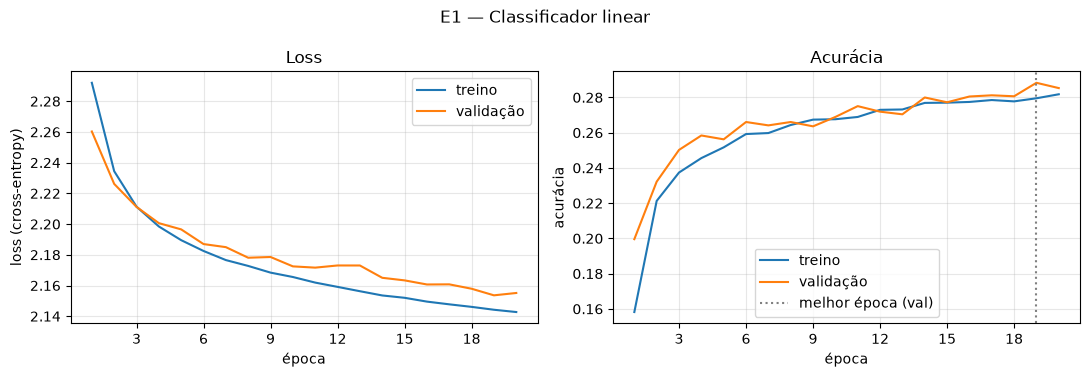

melhor época 19: train_loss=2.1442 val_loss=2.1536 | train_acc=0.2795 val_acc=0.2883 | test_acc=0.2402 | 0.5 min


In [8]:
run(1, 'Classificador linear', 'Linear 3072→10, SGD + L2',
    lambda: L.LinearClassifier(), dados='norm',
    epochs=20, batch_size=128, lr=1e-4, optimizer='sgd', weight_decay=1e-4);

### E2 — MLP baseline (código da aula)
A MLP do notebook da aula, sem alterações: 2 camadas ocultas de 500 neurônios, ReLU, Adam com lr = 1e-3, batch 100
e entrada apenas em [0, 1].

=== E2: MLP baseline ===


época  1/25 | treino loss 2.1650 acc 0.2092 | val loss 2.0044 acc 0.2554 | 10.2s


época  2/25 | treino loss 1.8923 acc 0.3130 | val loss 1.6974 acc 0.4233 | 29.9s


época  3/25 | treino loss 1.5688 acc 0.4610 | val loss 1.5051 acc 0.4840 | 28.1s


época  4/25 | treino loss 1.4573 acc 0.5023 | val loss 1.4219 acc 0.5235 | 32.5s


época  5/25 | treino loss 1.4096 acc 0.5223 | val loss 1.4742 acc 0.5059 | 29.1s


... (16 outputs left out)

época 22/25 | treino loss 1.2772 acc 0.5811 | val loss 1.3142 acc 0.5684 | 30.4s


época 23/25 | treino loss 1.2736 acc 0.5820 | val loss 1.3306 acc 0.5620 | 28.2s


época 24/25 | treino loss 1.2701 acc 0.5857 | val loss 1.2923 acc 0.5786 | 31.0s


época 25/25 | treino loss 1.2677 acc 0.5844 | val loss 1.2986 acc 0.5710 | 28.5s


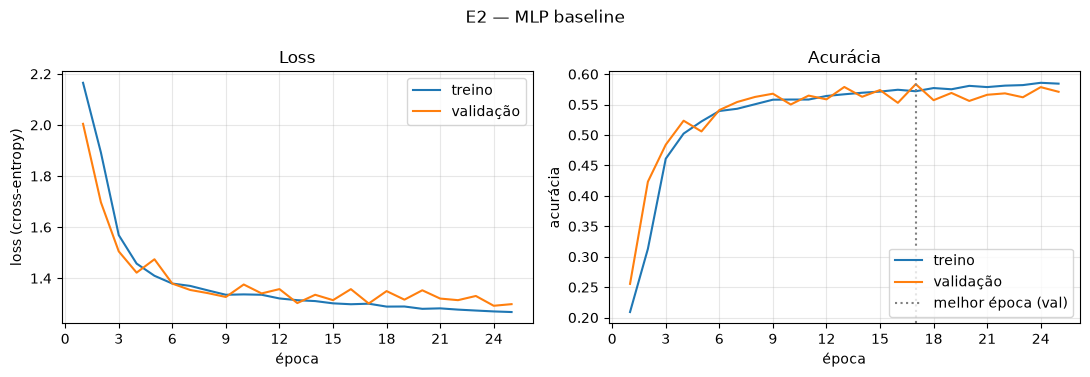

melhor época 17: train_loss=1.3004 val_loss=1.3011 | train_acc=0.5719 val_acc=0.5835 | test_acc=0.5501 | 12.0 min


In [9]:
run(2, 'MLP baseline', 'MLP 2×500, entrada em [0,1]',
    lambda: L.MLP([500, 500]), dados='bruto', pai=1,
    epochs=25, batch_size=100, lr=1e-3);

### E3 — E2 + normalização por canal

=== E3: MLP + normalização ===


época  1/25 | treino loss 1.1840 acc 0.6211 | val loss 0.9350 acc 0.7174 | 9.6s


época  2/25 | treino loss 0.8185 acc 0.7501 | val loss 0.7940 acc 0.7563 | 9.1s


época  3/25 | treino loss 0.7042 acc 0.7841 | val loss 0.7337 acc 0.7804 | 9.8s


época  4/25 | treino loss 0.6421 acc 0.8029 | val loss 0.7024 acc 0.7894 | 9.8s


época  5/25 | treino loss 0.5904 acc 0.8209 | val loss 0.6804 acc 0.7995 | 9.7s


... (16 outputs left out)

época 22/25 | treino loss 0.3198 acc 0.8995 | val loss 0.8351 acc 0.8249 | 12.5s


época 23/25 | treino loss 0.3109 acc 0.9022 | val loss 0.8443 acc 0.8302 | 13.0s


época 24/25 | treino loss 0.3039 acc 0.9044 | val loss 0.8434 acc 0.8204 | 9.2s


época 25/25 | treino loss 0.2999 acc 0.9050 | val loss 0.8777 acc 0.8215 | 9.4s


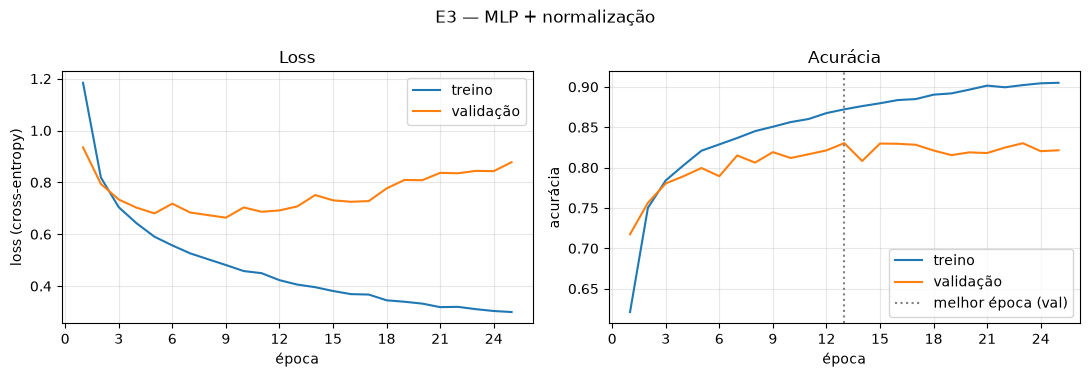

melhor época 13: train_loss=0.4058 val_loss=0.7073 | train_acc=0.8722 val_acc=0.8303 | test_acc=0.7948 | 4.4 min


In [10]:
run(3, 'MLP + normalização', 'E2 + normalização (média/desvio por canal)',
    lambda: L.MLP([500, 500]), dados='norm', pai=2,
    epochs=25, batch_size=100, lr=1e-3);

### E4 e E5 — Taxa de aprendizado (10× maior e 10× menor que a do E3)
Mesmo modelo do E3, mudando só a taxa de aprendizado: 1e-2 (E4) e 1e-4 (E5).

=== E4: MLP lr alta (1e-2) ===


época  1/25 | treino loss 2.5749 acc 0.1853 | val loss 2.2263 acc 0.1970 | 9.7s


época  2/25 | treino loss 2.2420 acc 0.1883 | val loss 2.2255 acc 0.1970 | 15.2s


época  3/25 | treino loss 2.2385 acc 0.1883 | val loss 2.2251 acc 0.1970 | 15.1s


época  4/25 | treino loss 2.2385 acc 0.1883 | val loss 2.2260 acc 0.1970 | 30.6s


época  5/25 | treino loss 2.2386 acc 0.1883 | val loss 2.2258 acc 0.1970 | 30.3s


... (16 outputs left out)

época 22/25 | treino loss 2.2386 acc 0.1883 | val loss 2.2249 acc 0.1970 | 31.7s


época 23/25 | treino loss 2.2386 acc 0.1883 | val loss 2.2249 acc 0.1970 | 30.3s


época 24/25 | treino loss 2.2386 acc 0.1883 | val loss 2.2261 acc 0.1970 | 32.5s


época 25/25 | treino loss 2.2384 acc 0.1883 | val loss 2.2255 acc 0.1970 | 30.2s


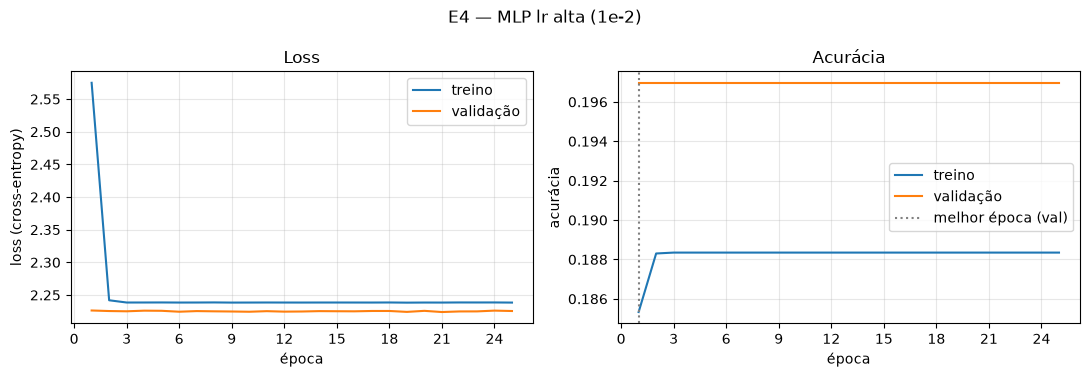

melhor época 1: train_loss=2.5749 val_loss=2.2263 | train_acc=0.1853 val_acc=0.1970 | test_acc=0.1959 | 11.7 min


In [11]:
run(4, 'MLP lr alta (1e-2)', 'E3 com lr = 1e-2',
    lambda: L.MLP([500, 500]), dados='norm', pai=3,
    epochs=25, batch_size=100, lr=1e-2);

=== E5: MLP lr baixa (1e-4) ===


época  1/25 | treino loss 1.3127 acc 0.5860 | val loss 0.9418 acc 0.7195 | 9.7s


época  2/25 | treino loss 0.8324 acc 0.7502 | val loss 0.7866 acc 0.7643 | 7.9s


época  3/25 | treino loss 0.6989 acc 0.7925 | val loss 0.6802 acc 0.8011 | 7.8s


época  4/25 | treino loss 0.6206 acc 0.8163 | val loss 0.6503 acc 0.8082 | 7.8s


época  5/25 | treino loss 0.5681 acc 0.8311 | val loss 0.6255 acc 0.8221 | 7.7s


... (16 outputs left out)

época 22/25 | treino loss 0.2616 acc 0.9227 | val loss 0.5302 acc 0.8578 | 7.8s


época 23/25 | treino loss 0.2496 acc 0.9260 | val loss 0.5571 acc 0.8550 | 7.8s


época 24/25 | treino loss 0.2393 acc 0.9290 | val loss 0.5479 acc 0.8601 | 7.7s


época 25/25 | treino loss 0.2268 acc 0.9328 | val loss 0.5455 acc 0.8594 | 8.0s


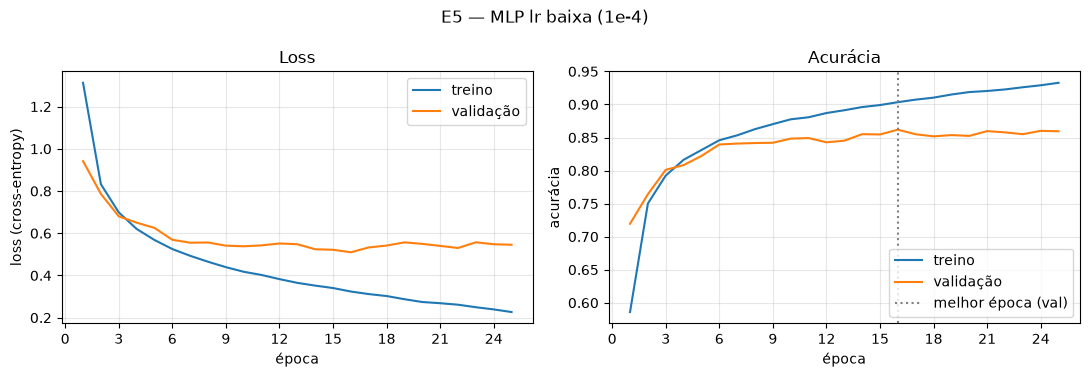

melhor época 16: train_loss=0.3240 val_loss=0.5100 | train_acc=0.9035 val_acc=0.8619 | test_acc=0.8345 | 3.5 min


In [12]:
run(5, 'MLP lr baixa (1e-4)', 'E3 com lr = 1e-4',
    lambda: L.MLP([500, 500]), dados='norm', pai=3,
    epochs=25, batch_size=100, lr=1e-4);

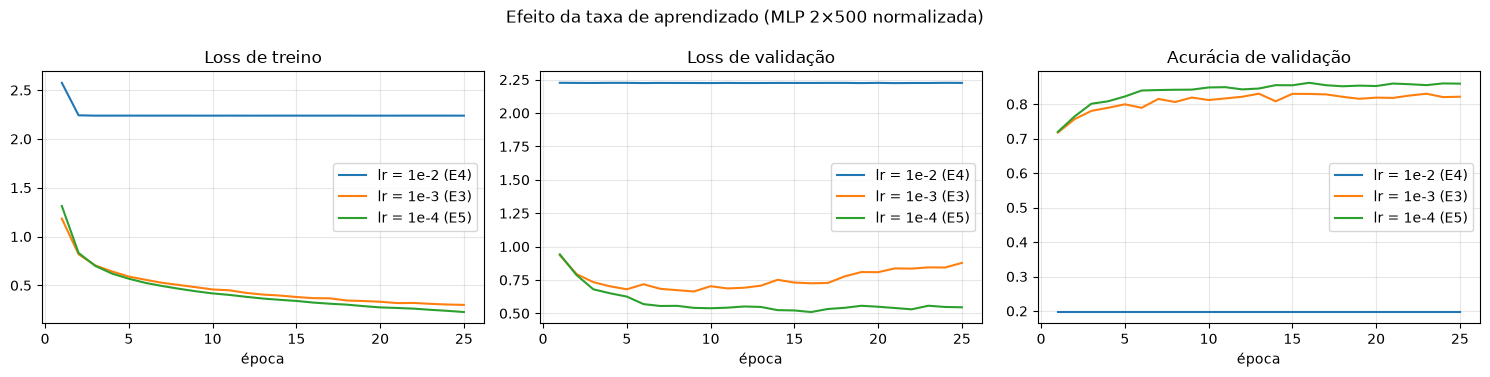

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for e, lr in [(4, '1e-2'), (3, '1e-3'), (5, '1e-4')]:
    h = json.load(open(f'resultados/E{e}.json'))['hist']
    ep = range(1, len(h['val_acc']) + 1)
    ax[0].plot(ep, h['train_loss'], label=f'lr = {lr} (E{e})')
    ax[1].plot(ep, h['val_loss'], label=f'lr = {lr} (E{e})')
    ax[2].plot(ep, h['val_acc'], label=f'lr = {lr} (E{e})')
ax[0].set(title='Loss de treino', xlabel='época'); ax[1].set(title='Loss de validação', xlabel='época')
ax[2].set(title='Acurácia de validação', xlabel='época')
for a in ax: a.grid(alpha=.3); a.legend()
plt.suptitle('Efeito da taxa de aprendizado (MLP 2×500 normalizada)'); plt.tight_layout()
plt.savefig('resultados/comparacao_lr.png', dpi=130); plt.show()

**Qual taxa de aprendizado seguir usando?** Os próximos experimentos partem do melhor dos três (E3, E4, E5)
segundo a acurácia de validação. A escolha é feita pelo código, não à mão.

In [14]:
def melhor(*exps):
    "Experimento com a maior acurácia de validação entre os indicados."
    return max((r for r in RESULTS if r['exp'] in exps), key=lambda r: r['val_acc'])

B_LR = melhor(3, 4, 5)
LR = B_LR['config']['lr']
print(f"Melhor taxa na validação: lr = {LR:g} (E{B_LR['exp']}, val_acc = {B_LR['val_acc']:.4f}).")
print(f"Os próximos experimentos partem do E{B_LR['exp']}.")

Melhor taxa na validação: lr = 0.0001 (E5, val_acc = 0.8619).
Os próximos experimentos partem do E5.


### E6 — mais camadas e neurônios (1024 → 512 → 256)

=== E6: MLP maior ===


época  1/25 | treino loss 1.2924 acc 0.5825 | val loss 0.9389 acc 0.7146 | 16.2s


época  2/25 | treino loss 0.8064 acc 0.7548 | val loss 0.7744 acc 0.7639 | 15.9s


época  3/25 | treino loss 0.6724 acc 0.7974 | val loss 0.6760 acc 0.7998 | 16.6s


época  4/25 | treino loss 0.5910 acc 0.8238 | val loss 0.6172 acc 0.8204 | 15.9s


época  5/25 | treino loss 0.5349 acc 0.8390 | val loss 0.6137 acc 0.8209 | 15.9s


... (16 outputs left out)

época 22/25 | treino loss 0.1822 acc 0.9447 | val loss 0.5817 acc 0.8616 | 16.5s


época 23/25 | treino loss 0.1696 acc 0.9477 | val loss 0.6304 acc 0.8514 | 17.0s


época 24/25 | treino loss 0.1561 acc 0.9525 | val loss 0.6007 acc 0.8623 | 17.6s


época 25/25 | treino loss 0.1477 acc 0.9551 | val loss 0.6341 acc 0.8565 | 16.9s


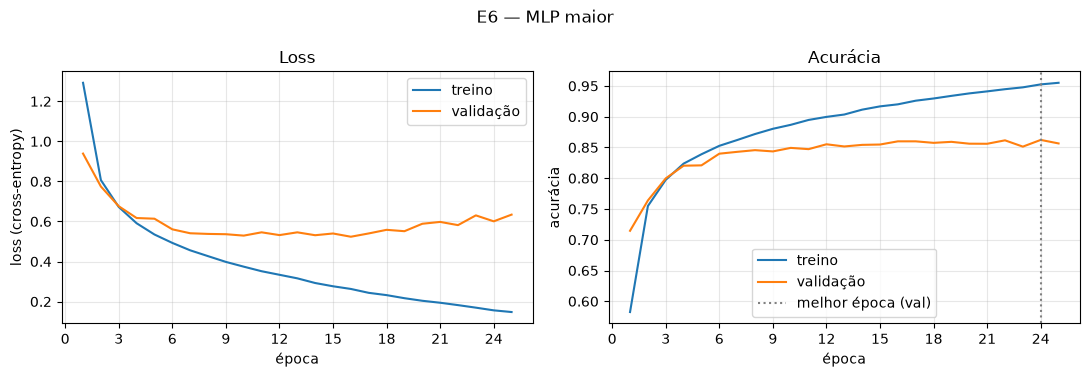

melhor época 24: train_loss=0.1561 val_loss=0.6007 | train_acc=0.9525 val_acc=0.8623 | test_acc=0.8357 | 7.0 min


In [15]:
run(6, 'MLP maior', f"E{B_LR['exp']} com 3 camadas ocultas: 1024-512-256",
    lambda: L.MLP([1024, 512, 256]), dados='norm', pai=B_LR['exp'],
    epochs=25, batch_size=100, lr=LR);

### E7 — E6 + Dropout 0,3
Regularização vista em aula: a cada passo de treino, 30% dos neurônios de cada camada oculta são zerados.

=== E7: MLP + dropout ===


época  1/25 | treino loss 1.5927 acc 0.4588 | val loss 1.0810 acc 0.6626 | 18.2s


época  2/25 | treino loss 1.0240 acc 0.6819 | val loss 0.8438 acc 0.7468 | 18.0s


época  3/25 | treino loss 0.8712 acc 0.7313 | val loss 0.7432 acc 0.7781 | 17.7s


época  4/25 | treino loss 0.7802 acc 0.7629 | val loss 0.6793 acc 0.7968 | 22.6s


época  5/25 | treino loss 0.7271 acc 0.7785 | val loss 0.6596 acc 0.8014 | 22.4s


... (16 outputs left out)

época 22/25 | treino loss 0.4277 acc 0.8659 | val loss 0.4507 acc 0.8643 | 18.3s


época 23/25 | treino loss 0.4231 acc 0.8684 | val loss 0.4438 acc 0.8691 | 18.8s


época 24/25 | treino loss 0.4095 acc 0.8730 | val loss 0.4466 acc 0.8645 | 21.9s


época 25/25 | treino loss 0.4071 acc 0.8736 | val loss 0.4484 acc 0.8649 | 21.7s


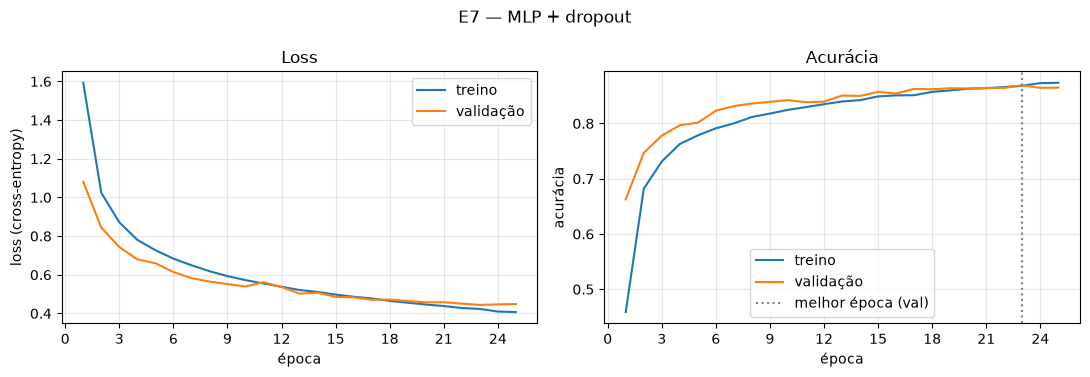

melhor época 23: train_loss=0.4231 val_loss=0.4438 | train_acc=0.8684 val_acc=0.8691 | test_acc=0.8455 | 8.2 min


In [16]:
run(7, 'MLP + dropout', 'E6 + dropout 0,3',
    lambda: L.MLP([1024, 512, 256], dropout=0.3), dados='norm', pai=6,
    epochs=25, batch_size=100, lr=LR);

### E8 — E7 + Batch Normalization
Normaliza as ativações de cada camada oculta dentro do mini-batch (a mesma ideia da normalização da entrada,
aplicada dentro da rede).

=== E8: MLP + dropout + BN ===


época  1/25 | treino loss 1.6308 acc 0.4584 | val loss 1.1020 acc 0.6723 | 24.0s


época  2/25 | treino loss 1.0991 acc 0.6572 | val loss 0.8784 acc 0.7312 | 19.3s


época  3/25 | treino loss 0.9358 acc 0.7064 | val loss 0.7397 acc 0.7733 | 23.9s


época  4/25 | treino loss 0.8486 acc 0.7343 | val loss 0.6665 acc 0.7962 | 19.6s


época  5/25 | treino loss 0.7949 acc 0.7525 | val loss 0.6395 acc 0.8078 | 20.2s


... (16 outputs left out)

época 22/25 | treino loss 0.5010 acc 0.8413 | val loss 0.4289 acc 0.8687 | 20.1s


época 23/25 | treino loss 0.4946 acc 0.8431 | val loss 0.4344 acc 0.8649 | 19.5s


época 24/25 | treino loss 0.4837 acc 0.8471 | val loss 0.4249 acc 0.8702 | 19.4s


época 25/25 | treino loss 0.4823 acc 0.8467 | val loss 0.4428 acc 0.8631 | 19.5s


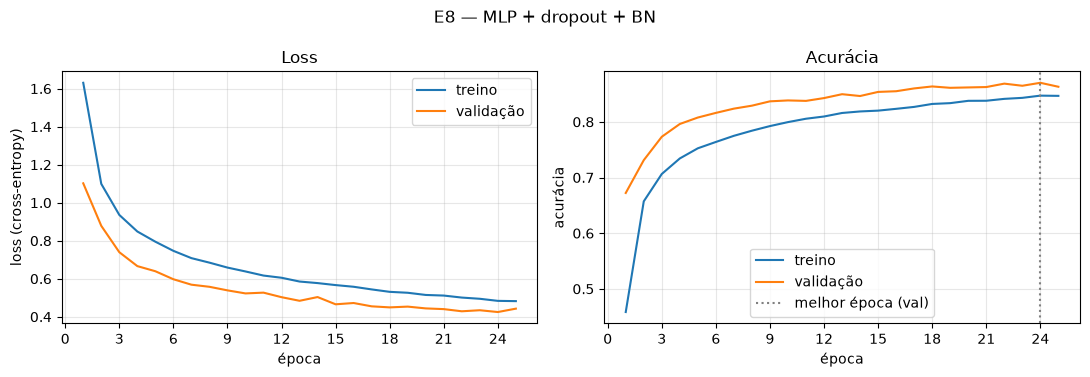

melhor época 24: train_loss=0.4837 val_loss=0.4249 | train_acc=0.8471 val_acc=0.8702 | test_acc=0.8440 | 8.6 min


In [17]:
run(8, 'MLP + dropout + BN', 'E7 + BatchNorm',
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm', pai=7,
    epochs=25, batch_size=100, lr=LR);

### E9 — E8 com a outra taxa de aprendizado
A BatchNorm muda a escala das ativações e costuma permitir taxas maiores, então a taxa escolhida antes (sem BN)
pode não ser mais a melhor. Repetimos o E8 trocando só a taxa (1e-3 ↔ 1e-4) e seguimos com a melhor das duas.

=== E9: MLP + BN, lr 0.001 ===


época  1/25 | treino loss 1.4742 acc 0.5025 | val loss 0.9965 acc 0.6908 | 23.9s


época  2/25 | treino loss 1.0217 acc 0.6741 | val loss 0.7976 acc 0.7517 | 17.6s


época  3/25 | treino loss 0.8761 acc 0.7218 | val loss 0.7121 acc 0.7789 | 18.7s


época  4/25 | treino loss 0.8076 acc 0.7451 | val loss 0.6483 acc 0.7993 | 20.4s


época  5/25 | treino loss 0.7506 acc 0.7625 | val loss 0.6186 acc 0.8108 | 18.7s


... (16 outputs left out)

época 22/25 | treino loss 0.4675 acc 0.8503 | val loss 0.4392 acc 0.8624 | 19.9s


época 23/25 | treino loss 0.4599 acc 0.8533 | val loss 0.4292 acc 0.8701 | 23.8s


época 24/25 | treino loss 0.4487 acc 0.8579 | val loss 0.4350 acc 0.8643 | 24.2s


época 25/25 | treino loss 0.4436 acc 0.8580 | val loss 0.4409 acc 0.8625 | 20.3s


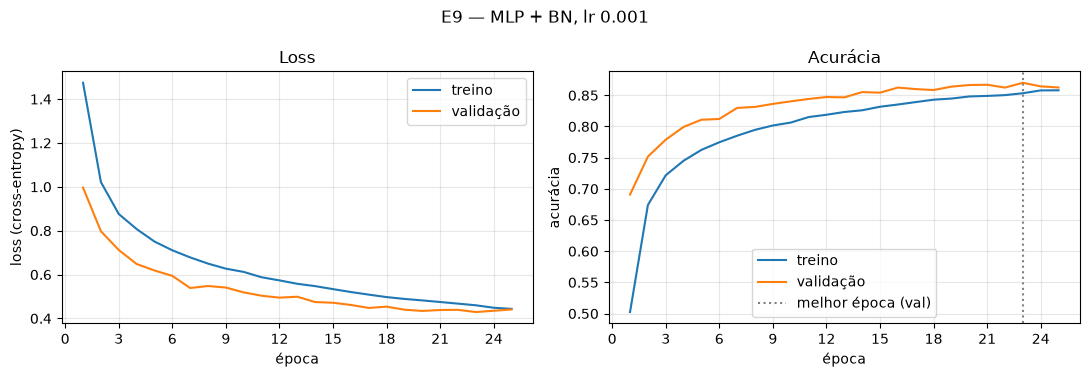

melhor época 23: train_loss=0.4599 val_loss=0.4292 | train_acc=0.8533 val_acc=0.8701 | test_acc=0.8439 | 8.7 min

Com BatchNorm, a melhor taxa na validação é lr = 0.0001 (E8). Seguimos a partir dele.


In [18]:
LR_ALT = 1e-3 if LR != 1e-3 else 1e-4
run(9, f'MLP + BN, lr {LR_ALT:g}', f'E8 com lr = {LR_ALT:g}',
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm', pai=8,
    epochs=25, batch_size=100, lr=LR_ALT);
B_BN = melhor(8, 9)
print(f"\nCom BatchNorm, a melhor taxa na validação é lr = {B_BN['config']['lr']:g} (E{B_BN['exp']}). Seguimos a partir dele.")

### E10 — batch 256 (em vez de 100)
Batch maior: gradiente menos ruidoso, mas menos atualizações por época.

=== E10: MLP batch 256 ===


época  1/25 | treino loss 1.7400 acc 0.4213 | val loss 1.1906 acc 0.6755 | 13.8s


época  2/25 | treino loss 1.1487 acc 0.6512 | val loss 0.8970 acc 0.7452 | 14.5s


época  3/25 | treino loss 0.9601 acc 0.7049 | val loss 0.7720 acc 0.7670 | 14.9s


época  4/25 | treino loss 0.8512 acc 0.7361 | val loss 0.6986 acc 0.7887 | 14.6s


época  5/25 | treino loss 0.7906 acc 0.7523 | val loss 0.6480 acc 0.8045 | 14.6s


... (16 outputs left out)

época 22/25 | treino loss 0.4862 acc 0.8466 | val loss 0.4336 acc 0.8640 | 13.9s


época 23/25 | treino loss 0.4721 acc 0.8510 | val loss 0.4307 acc 0.8699 | 16.6s


época 24/25 | treino loss 0.4641 acc 0.8534 | val loss 0.4411 acc 0.8631 | 16.3s


época 25/25 | treino loss 0.4646 acc 0.8530 | val loss 0.4411 acc 0.8631 | 14.2s


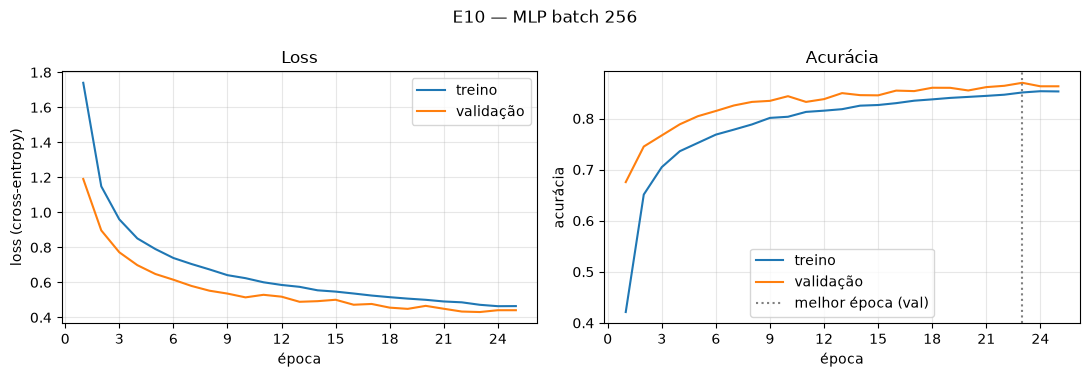

melhor época 23: train_loss=0.4721 val_loss=0.4307 | train_acc=0.8510 val_acc=0.8699 | test_acc=0.8398 | 6.1 min

Melhor tamanho de batch na validação: 100 (E8). Seguimos a partir dele.


In [19]:
run(10, 'MLP batch 256', f"E{B_BN['exp']} com batch 256",
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm', pai=B_BN['exp'],
    **dict(B_BN['config'], batch_size=256));
B_BATCH = melhor(B_BN['exp'], 10)
print(f"\nMelhor tamanho de batch na validação: {B_BATCH['config']['batch_size']} (E{B_BATCH['exp']}). Seguimos a partir dele.")

### E11 — taxa de aprendizado com decaimento cosseno
A taxa começa no valor escolhido e cai suavemente até zero: passos grandes no início e ajuste fino no fim.

=== E11: MLP + lr cosseno ===


época  1/25 | treino loss 1.6308 acc 0.4584 | val loss 1.1020 acc 0.6723 | 20.8s


época  2/25 | treino loss 1.0966 acc 0.6580 | val loss 0.8768 acc 0.7281 | 24.1s


época  3/25 | treino loss 0.9327 acc 0.7070 | val loss 0.7446 acc 0.7730 | 19.3s


época  4/25 | treino loss 0.8467 acc 0.7335 | val loss 0.6651 acc 0.7968 | 19.6s


época  5/25 | treino loss 0.7929 acc 0.7512 | val loss 0.6308 acc 0.8112 | 19.4s


... (16 outputs left out)

época 22/25 | treino loss 0.4461 acc 0.8590 | val loss 0.4039 acc 0.8747 | 19.3s


época 23/25 | treino loss 0.4421 acc 0.8614 | val loss 0.4042 acc 0.8767 | 19.4s


época 24/25 | treino loss 0.4352 acc 0.8642 | val loss 0.4009 acc 0.8778 | 19.3s


época 25/25 | treino loss 0.4382 acc 0.8636 | val loss 0.4029 acc 0.8762 | 18.6s


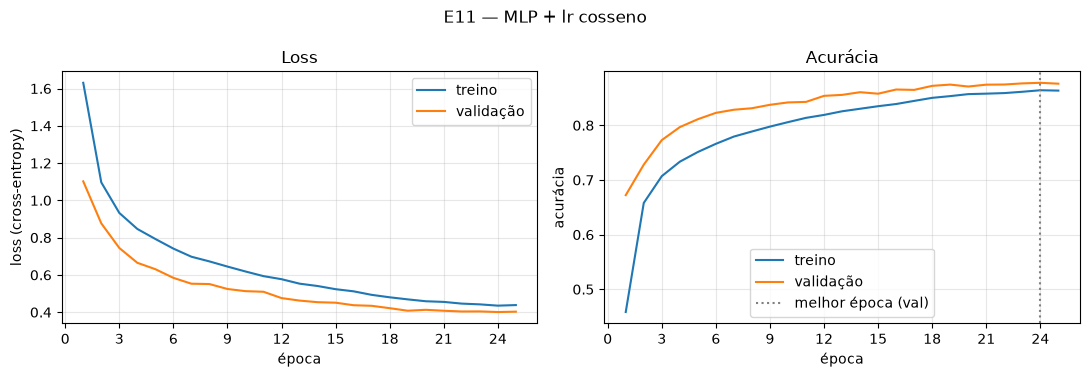

melhor época 24: train_loss=0.4352 val_loss=0.4009 | train_acc=0.8642 val_acc=0.8778 | test_acc=0.8546 | 8.4 min

Melhor MLP na validação: E11 — MLP + lr cosseno (val_acc = 0.8778, test_acc = 0.8546)


In [20]:
run(11, 'MLP + lr cosseno', f"E{B_BATCH['exp']} + decaimento cosseno da lr",
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm', pai=B_BATCH['exp'],
    **dict(B_BATCH['config'], scheduler='cosine'));
B_MLP = melhor(*range(2, 12))
print(f"\nMelhor MLP na validação: E{B_MLP['exp']} — {B_MLP['nome']} (val_acc = {B_MLP['val_acc']:.4f}, test_acc = {B_MLP['test_acc']:.4f})")

### E12 — CNN (rede convolucional)
O enunciado deixa a arquitetura livre e cita o "número de filtros". A MLP trata cada pixel como uma entrada
independente; a convolução aplica os mesmos filtros em toda a imagem e aproveita a vizinhança dos pixels.
Arquitetura: 3 blocos convolucionais (32 → 64 → 128 filtros 3×3, BatchNorm, ReLU, max-pool) e um classificador
totalmente conectado com dropout 0,3. Treino: Adam, lr 1e-3 com decaimento cosseno, batch 128, 20 épocas.

=== E12: CNN ===


época  1/20 | treino loss 1.0688 acc 0.6366 | val loss 0.3896 acc 0.8814 | 149.7s


época  2/20 | treino loss 0.4394 acc 0.8672 | val loss 0.3032 acc 0.9124 | 155.3s


época  3/20 | treino loss 0.3599 acc 0.8933 | val loss 0.2622 acc 0.9249 | 160.5s


época  4/20 | treino loss 0.3137 acc 0.9102 | val loss 0.2517 acc 0.9271 | 156.6s


época  5/20 | treino loss 0.2723 acc 0.9216 | val loss 0.2229 acc 0.9358 | 158.4s


... (11 outputs left out)

época 17/20 | treino loss 0.0617 acc 0.9812 | val loss 0.2336 acc 0.9522 | 159.2s


época 18/20 | treino loss 0.0569 acc 0.9833 | val loss 0.2343 acc 0.9543 | 161.9s


época 19/20 | treino loss 0.0530 acc 0.9845 | val loss 0.2350 acc 0.9545 | 157.3s


época 20/20 | treino loss 0.0529 acc 0.9844 | val loss 0.2361 acc 0.9541 | 154.1s


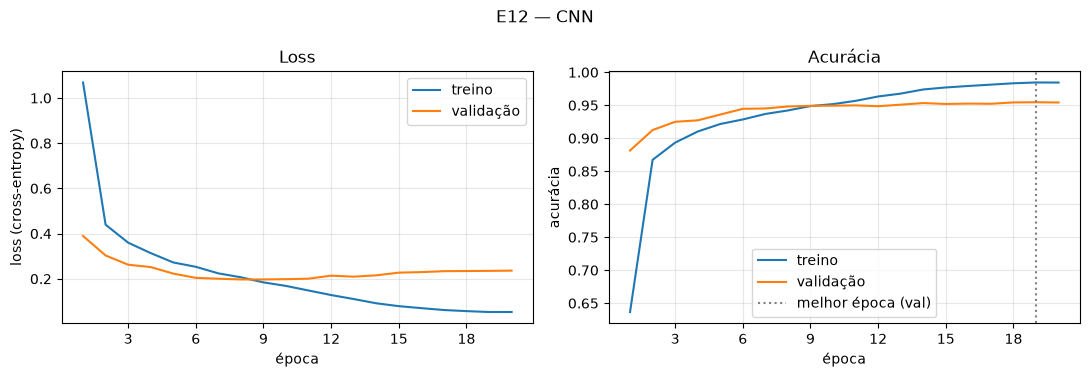

melhor época 19: train_loss=0.0530 val_loss=0.2350 | train_acc=0.9845 val_acc=0.9545 | test_acc=0.9517 | 52.5 min


In [21]:
run(12, 'CNN', 'CNN 3 blocos conv (32-64-128 filtros)',
    lambda: L.CNN(dropout=0.3), dados='norm', pai=B_MLP['exp'],
    epochs=20, batch_size=128, lr=1e-3, scheduler='cosine');

### E13 — E12 + data augmentation
Translação aleatória de até 2 pixels em cada imagem de treino. Não usamos espelhamento horizontal, que muda o
significado de alguns dígitos.

=== E13: CNN + augmentation ===


época  1/20 | treino loss 1.0142 acc 0.6578 | val loss 0.3436 acc 0.8908 | 152.5s


época  2/20 | treino loss 0.4521 acc 0.8649 | val loss 0.2801 acc 0.9146 | 158.2s


época  3/20 | treino loss 0.3769 acc 0.8898 | val loss 0.2445 acc 0.9275 | 155.2s


época  4/20 | treino loss 0.3322 acc 0.9051 | val loss 0.2255 acc 0.9341 | 158.8s


época  5/20 | treino loss 0.2981 acc 0.9167 | val loss 0.2210 acc 0.9346 | 154.6s


... (11 outputs left out)

época 17/20 | treino loss 0.1362 acc 0.9648 | val loss 0.1638 acc 0.9574 | 188.2s


época 18/20 | treino loss 0.1298 acc 0.9670 | val loss 0.1631 acc 0.9570 | 239.4s


época 19/20 | treino loss 0.1246 acc 0.9679 | val loss 0.1616 acc 0.9580 | 177.6s


época 20/20 | treino loss 0.1229 acc 0.9685 | val loss 0.1614 acc 0.9578 | 165.7s


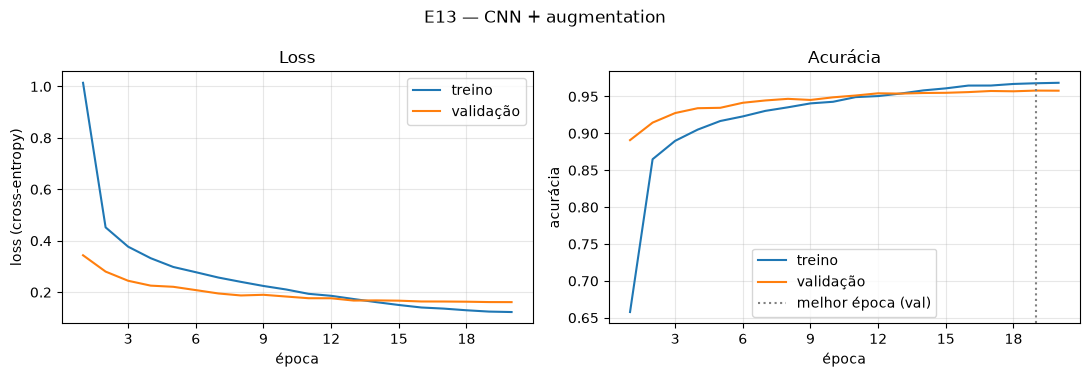

melhor época 19: train_loss=0.1246 val_loss=0.1616 | train_acc=0.9679 val_acc=0.9580 | test_acc=0.9627 | 55.8 min


In [22]:
run(13, 'CNN + augmentation', 'E12 + translação aleatória de ±2 px',
    lambda: L.CNN(dropout=0.3), dados='norm', pai=12,
    epochs=20, batch_size=128, lr=1e-3, scheduler='cosine', augment_shift=2);

## 4. Comparação dos experimentos

In [23]:
df = pd.DataFrame(RESULTS).drop(columns=['config'])
df['gap_treino_val'] = df['train_acc'] - df['val_acc']
df.to_csv('resultados/tabela_experimentos.csv', index=False)
fmt = {c: '{:.4f}' for c in ['train_loss', 'val_loss', 'train_acc', 'val_acc', 'test_acc', 'gap_treino_val']}
df.style.format(fmt | {'tempo_min': '{:.1f}', 'params': '{:,}'})

,exp,nome,modificacao,dados,pai,params,epocas,melhor_epoca,train_loss,val_loss,train_acc,val_acc,test_acc,tempo_min,gap_treino_val
0,1,Classificador linear,"Linear 3072→10, SGD + L2",norm,nan,"30,730",20,19,2.1442,2.1536,0.2795,0.2883,0.2402,0.5,-0.0088
1,2,MLP baseline,"MLP 2×500, entrada em [0,1]",bruto,1.000000,"1,792,010",25,17,1.3004,1.3011,0.5719,0.5835,0.5501,12.0,-0.0117
2,3,MLP + normalização,E2 + normalização (média/desvio por canal),norm,2.000000,"1,792,010",25,13,0.4058,0.7073,0.8722,0.8303,0.7948,4.4,0.0418
3,4,MLP lr alta (1e-2),E3 com lr = 1e-2,norm,3.000000,"1,792,010",25,1,2.5749,2.2263,0.1853,0.1970,0.1959,11.7,-0.0116
4,5,MLP lr baixa (1e-4),E3 com lr = 1e-4,norm,3.000000,"1,792,010",25,16,0.3240,0.5100,0.9035,0.8619,0.8345,3.5,0.0416
5,6,MLP maior,E5 com 3 camadas ocultas: 1024-512-256,norm,5.000000,"3,805,450",25,24,0.1561,0.6007,0.9525,0.8623,0.8357,7.0,0.0902
6,7,MLP + dropout,"E6 + dropout 0,3",norm,6.000000,"3,805,450",25,23,0.4231,0.4438,0.8684,0.8691,0.8455,8.2,-0.0007
7,8,MLP + dropout + BN,E7 + BatchNorm,norm,7.000000,"3,809,034",25,24,0.4837,0.4249,0.8471,0.8702,0.8440,8.6,-0.0231
8,9,"MLP + BN, lr 0.001",E8 com lr = 0.001,norm,8.000000,"3,809,034",25,23,0.4599,0.4292,0.8533,0.8701,0.8439,8.7,-0.0167
9,10,MLP batch 256,E8 com batch 256,norm,8.000000,"3,809,034",25,23,0.4721,0.4307,0.8510,0.8699,0.8398,6.1,-0.0189


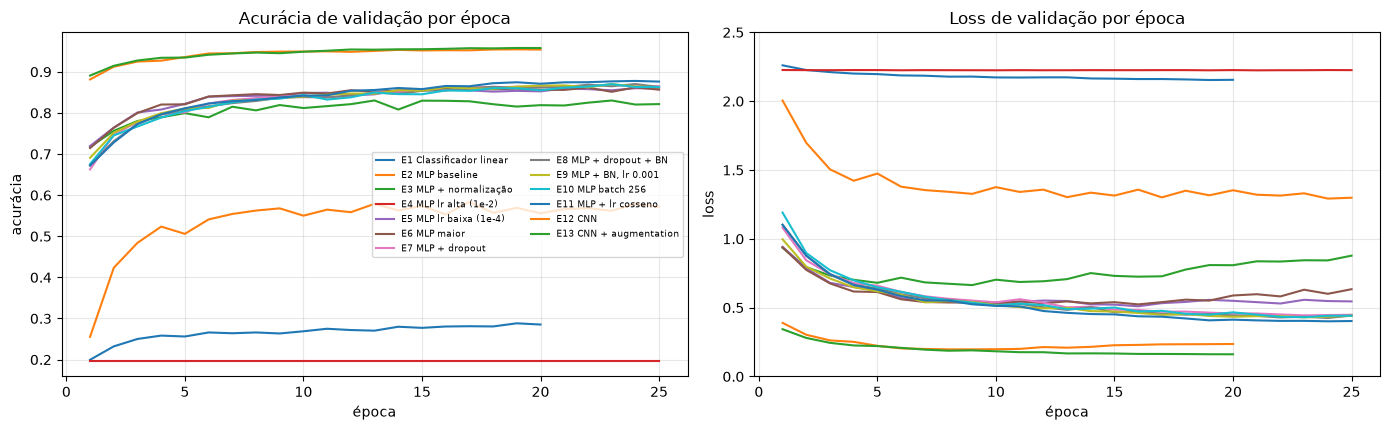

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for r in RESULTS:
    h = json.load(open(f"resultados/E{r['exp']}.json"))['hist']
    ax[0].plot(range(1, len(h['val_acc']) + 1), h['val_acc'], label=f"E{r['exp']} {r['nome']}")
    ax[1].plot(range(1, len(h['val_loss']) + 1), h['val_loss'], label=f"E{r['exp']}")
ax[0].set(title='Acurácia de validação por época', xlabel='época', ylabel='acurácia')
ax[1].set(title='Loss de validação por época', xlabel='época', ylabel='loss', ylim=(0, 2.5))
for a in ax: a.grid(alpha=.3)
ax[0].legend(fontsize=6.5, ncol=2); plt.tight_layout(); plt.savefig('resultados/comparacao_validacao.png', dpi=130); plt.show()

## 5. Escolha do modelo
Critério: **maior acurácia de validação**. O teste não participa da escolha.

In [25]:
best = max(RESULTS, key=lambda r: r['val_acc'])
print(f"Modelo escolhido: E{best['exp']} — {best['nome']}")
print(f"val_acc = {best['val_acc']:.4f} | test_acc = {best['test_acc']:.4f} | melhor época {best['melhor_epoca']} de {best['epocas']}")
with open('resultados/melhor_modelo.json', 'w') as f:
    json.dump(best, f, indent=1)

Modelo escolhido: E13 — CNN + augmentation
val_acc = 0.9580 | test_acc = 0.9627 | melhor época 19 de 20


## 6. Modelo final: retreino com todo o conjunto de treino

O enunciado permite que a versão final use todo o `train`. Com a configuração já escolhida pela validação
(arquitetura, hiperparâmetros e número de épocas do experimento vencedor), retreinamos o modelo com
**treino + validação (73.257 imagens)**, com a mesma semente. Nada é ajustado nesta etapa: não há mais validação,
e o modelo fica com os pesos da última época (a taxa de aprendizado com decaimento cosseno termina em zero, então
o fim do treino é estável). O teste continua servindo só para relatar o resultado.

época  1/20 | treino loss 0.8538 acc 0.7188 | 178.9s


época  2/20 | treino loss 0.3779 acc 0.8892 | 174.3s


época  3/20 | treino loss 0.3131 acc 0.9102 | 176.5s


época  4/20 | treino loss 0.2795 acc 0.9213 | 179.4s


época  5/20 | treino loss 0.2551 acc 0.9297 | 176.1s


época  6/20 | treino loss 0.2373 acc 0.9344 | 176.6s


... (11 outputs left out)

época 18/20 | treino loss 0.1051 acc 0.9724 | 168.9s


época 19/20 | treino loss 0.1030 acc 0.9734 | 164.3s


época 20/20 | treino loss 0.0990 acc 0.9743 | 167.7s



Modelo final (E13 retreinado com treino + validação): test_acc = 0.9639 (o mesmo modelo treinado só com 90% teve 0.9627) | 59.9 min


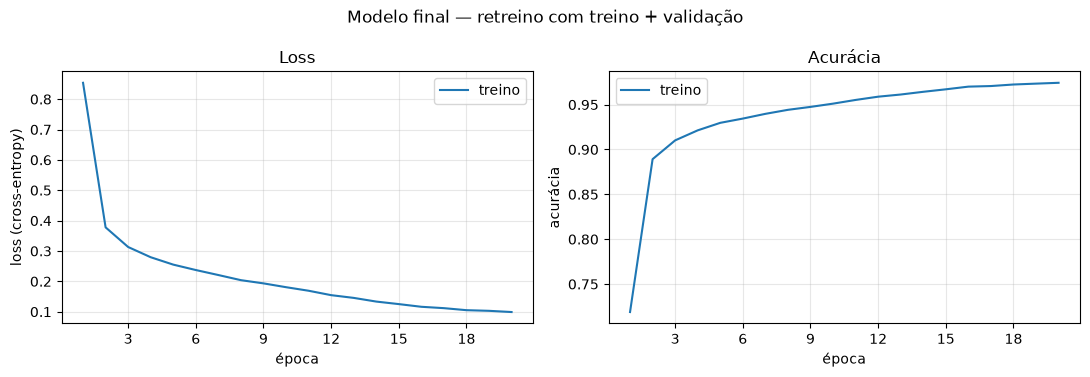

pesos salvos em melhor_modelo.pt


In [26]:
make_model, dados_best, kw_best = REGISTRY[best['exp']]
usa_norm = dados_best == 'norm'
mean_f, std_f = L.compute_norm_stats(X_all) if usa_norm else (None, None)   # estatísticas de todo o treino
prep = lambda X: L.preprocess(X, mean_f, std_f) if usa_norm else L.preprocess(X)

L.set_seed(SEED)
final_model = make_model()
t0 = time.time()
hist_final = L.train_model(final_model, dict(X_train=prep(X_all), y_train=y_all), seed=SEED, device=device, **kw_best)
X_test_f = prep(X_test_u8)
final_test_loss, final_test_acc = L.evaluate(final_model, X_test_f, y_test, device=device)
print(f"\nModelo final (E{best['exp']} retreinado com treino + validação): test_acc = {final_test_acc:.4f} "
      f"(o mesmo modelo treinado só com 90% teve {best['test_acc']:.4f}) | {(time.time() - t0) / 60:.1f} min")

torch.save({'exp': best['exp'], 'nome': best['nome'], 'state_dict': final_model.state_dict(),
            'mean': mean_f, 'std': std_f, 'dados': dados_best, 'config': kw_best,
            'val_acc_selecao': best['val_acc'], 'test_acc': final_test_acc}, 'melhor_modelo.pt')
with open('resultados/final.json', 'w') as f:
    json.dump({'exp': best['exp'], 'nome': best['nome'], 'n_treino': len(X_all), 'hist': hist_final,
               'test_loss': final_test_loss, 'test_acc': final_test_acc,
               'test_acc_selecao': best['test_acc'], 'val_acc_selecao': best['val_acc']}, f, indent=1)
L.plot_history(hist_final, 'Modelo final — retreino com treino + validação', 'resultados/final_curvas.png'); plt.show()
print('pesos salvos em melhor_modelo.pt')

### Matriz de confusão do modelo final no teste

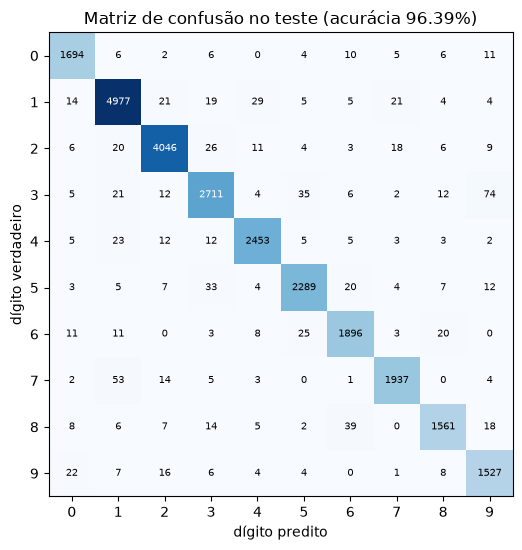

acurácia por dígito: {0: 0.9713, 1: 0.9761, 2: 0.9752, 3: 0.9407, 4: 0.9723, 5: 0.9602, 6: 0.959, 7: 0.9594, 8: 0.9404, 9: 0.9574}
confusões mais comuns (verdadeiro → predito): [(3, 9, 74), (7, 1, 53), (8, 6, 39), (3, 5, 35), (5, 3, 33)]


In [27]:
pred_test = L.predict(final_model, X_test_f, device=device)
cm = L.confusion_matrix(y_test, pred_test)
acc_classe = cm.diag().float() / cm.sum(1).float()

fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(cm, cmap='Blues')
for i in range(10):
    for j in range(10):
        v = int(cm[i, j])
        ax.text(j, i, v, ha='center', va='center', fontsize=7, color='white' if v > cm.max() / 2 else 'black')
ax.set(xticks=range(10), yticks=range(10), xlabel='dígito predito', ylabel='dígito verdadeiro',
       title=f'Matriz de confusão no teste (acurácia {final_test_acc:.2%})')
plt.tight_layout(); plt.savefig('resultados/final_confusao.png', dpi=130); plt.show()

print('acurácia por dígito:', {d: round(float(a), 4) for d, a in enumerate(acc_classe)})
erros = cm.clone(); erros.fill_diagonal_(0)
top = torch.topk(erros.flatten(), 5)
print('confusões mais comuns (verdadeiro → predito):',
      [(int(i) // 10, int(i) % 10, int(v)) for v, i in zip(top.values, top.indices)])
with open('resultados/final_confusao.json', 'w') as f:
    json.dump({'cm': cm.tolist(), 'acc_classe': acc_classe.tolist()}, f)

## 7. Predição do conjunto adicional
Feita **somente agora**, com o modelo final já definido. O pré-processamento é o mesmo do treino do modelo final
(mesma média e desvio). As imagens são lidas em **ordem do nome do arquivo** (ordenação numérica: `2.png` antes de
`10.png`), e o arquivo de saída tem um inteiro de 0 a 9 por linha, na mesma ordem.

As imagens do professor devem estar na pasta `extra/` (conteúdo de `images.zip`).

In [28]:
NOMES = 'JOAOPEDRO_SAMYR_VALBER'
PASTA_EXTRA = 'extra'

if os.path.isdir(PASTA_EXTRA):
    nomes_arq, X_extra_u8 = L.load_image_folder(PASTA_EXTRA)
    preds = L.predict(final_model, prep(X_extra_u8), device=device)
    saida = f'{NOMES}_RESULTS.txt'
    L.write_results(preds, saida)
    print(f'{len(preds)} imagens -> {saida}')
    print('primeiros arquivos:', nomes_arq[:5], '... último:', nomes_arq[-1])
    print('distribuição das predições:', np.bincount(preds.numpy(), minlength=10))
else:
    print(f'Pasta {PASTA_EXTRA}/ não encontrada: baixe o conjunto adicional e rode esta célula de novo.')

203856 imagens -> JOAOPEDRO_SAMYR_VALBER_RESULTS.txt
primeiros arquivos: ['000000.png', '000001.png', '000002.png', '000003.png', '000004.png'] ... último: 203855.png
distribuição das predições: [20297 21504 20639 20383 20226 20368 20165 20154 19995 20125]
